# Machine Learning ki Chauthi Class: KNN Classifier 🏘️

**AI for Everyone** | Instructor: Mian Muhammad Azam Ayaz

Pichli class mein humne **Logistic Regression** se diabetes predict kiya tha. Aaj **wohi sawal** ek bilkul alag tareeqe se hal karein ge: **K-Nearest Neighbors (KNN)**.

Aaj kya seekhenge:
1. **KNN** kya hai aur kaise kaam karta hai (padosiyon wali misaal)
2. **Distance** kaise naapte hain (Euclidean Distance)
3. **Lazy Learner** kya hota hai (KNN mein training kyun nahi hoti)
4. KNN ke liay **Feature Scaling** itna zaroori kyun hai
5. **K** ka asar: Overfitting aur Underfitting graph pe dekhna
6. Cross Validation se **best K** chunna, aur `weights` parameter
7. KNN vs Logistic Regression ka muqabla
8. Model ko **Pickle** mein save karna, aur naye mareez ke **padosi** dekhna

Dataset: wohi `diabetes.csv` (768 khawateen ka medical data)

> ⚠️ Ye notebook sirf **seekhne** ke liay hai. Asal mein diabetes ki tashkhees sirf doctor aur lab test se hoti hai.

---
## Part 1: KNN kya hai? 🤔

### Ek kahawat se shuru karte hain
> **"Aadmi apni sangat se pehchana jata hai."** 👥

KNN bilkul isi idea pe chalta hai. Kisi naye insaan ke baare mein faisla karna ho, to dekho **us jaise log** kaun hain, aur unki **aksariyat** kya hai.

**Definition:** K-Nearest Neighbors (KNN) ek Supervised Learning algorithm hai jo naye data point ke **K sab se qareebi padosi** (training data mein se) dhoondta hai, aur unki **majority vote** se faisla karta hai.

### Misaal 🏘️
Ek naya mareez aaya. K = 5 rakha. Model ne training data mein se **5 sab se milte julte mareez** dhoonde:
- 4 ko diabetes thi 🔴🔴🔴🔴
- 1 ko nahi thi 🔵

Majority = Diabetes. To faisla: **Diabetes (1)**, aur chance = 4/5 = **80%**.

### KNN ke steps
1. **K** chuno (kitne padosi dekhne hain)
2. Naye point ka **har training point se distance** naapo
3. Sab se **kam distance wale K points** chuno
4. Unme jo class **zyada** hai, wohi jawab ✅

### Ye "Lazy Learner" kyun kehlata hai? 😴
Linear aur Logistic Regression training ke waqt ek **formula seekhte** thay (m aur c). Logistic Regression ne to `max_iter` qadam bhi liay thay.

KNN **kuch nahi seekhta!** `.fit()` mein ye bas saara training data **yaad (save)** kar leta hai. Asal kaam tab hota hai jab naya point aata hai. Isliay:
- **Training:** bohat tez ⚡ (sirf data save karna)
- **Prediction:** slow 🐢 (har baar saare points se distance naapna)
- Is mein **koi epoch ya iteration nahi** hoti

### Distance kaise naapte hain? 📏

Sab se common tareeqa **Euclidean Distance** hai, yani do points ke beech **seedhi line ki lambai**. School ka Pythagoras theorem yaad hai? Bilkul wohi!

$$ distance = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2} $$

Zyada features hon to har feature ka farq square kar ke jor do, phir square root:

$$ distance = \sqrt{(Glucose_1 - Glucose_2)^2 + (BMI_1 - BMI_2)^2 + ...} $$

## Step 1: Libraries import karna 📦

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Sab libraries load ho gayin ✅")

Sab libraries load ho gayin ✅


### Chhota sa demo: KNN haath se chalate hain ✋

Sirf 8 mareez hain aur 2 features (Glucose aur BMI). Ek naya mareez aaya hai. Dekhte hain KNN kaise faisla karta hai.

In [2]:
toy = pd.DataFrame({
    "Glucose": [85, 90, 100, 110, 150, 160, 170, 180],
    "BMI":     [22, 26, 24, 30, 33, 29, 38, 35],
    "Outcome": [0,   0,  0,  0,  1,  0,  1,  1]
})

new_patient = {"Glucose": 155, "BMI": 32}

# Step 2: har mareez se distance (Pythagoras!)
toy["Distance"] = np.sqrt((toy["Glucose"] - new_patient["Glucose"])**2 +
                          (toy["BMI"] - new_patient["BMI"])**2).round(1)

# Step 3: distance ke hisaab se sort karo
toy.sort_values("Distance")

,Glucose,BMI,Outcome,Distance
4,150,33,1,5.1
5,160,29,0,5.8
6,170,38,1,16.2
7,180,35,1,25.2
3,110,30,0,45.0
2,100,24,0,55.6
1,90,26,0,65.3
0,85,22,0,70.7


3 sab se qareebi padosiyon ke votes:
  Diabetes (1): 2
  No Diabetes (0): 1

Faisla: Diabetes 🔴


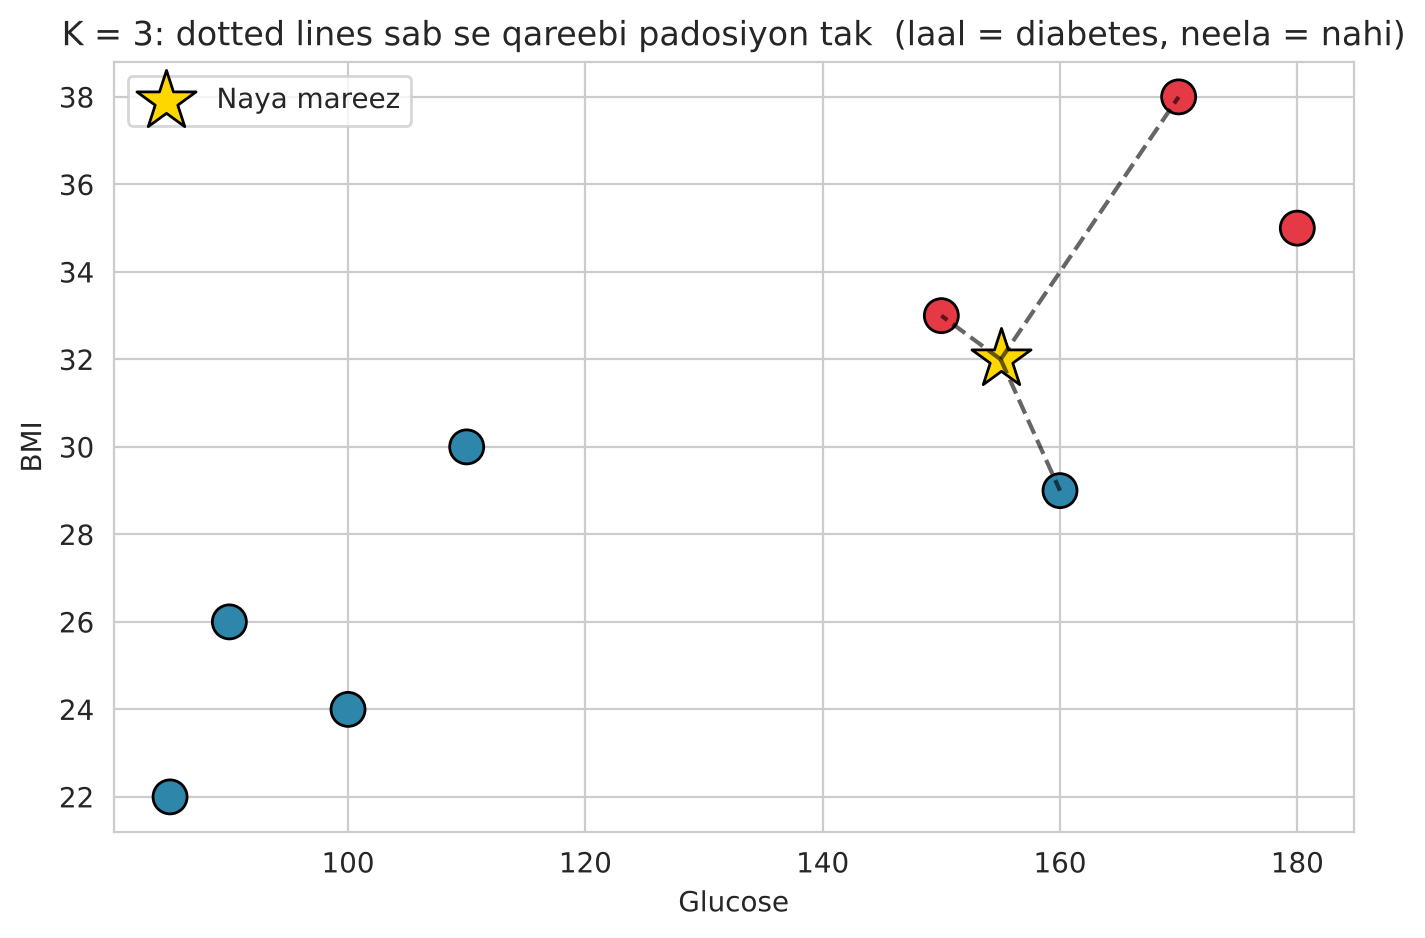

In [3]:
K = 3
nearest = toy.sort_values("Distance").head(K)

votes = nearest["Outcome"].value_counts()
print(f"{K} sab se qareebi padosiyon ke votes:")
print(f"  Diabetes (1): {votes.get(1, 0)}")
print(f"  No Diabetes (0): {votes.get(0, 0)}")
print()
decision = 1 if votes.get(1, 0) > votes.get(0, 0) else 0
print("Faisla:", "Diabetes 🔴" if decision == 1 else "No Diabetes 🔵")

# Graph
colors = toy["Outcome"].map({0: "#2E86AB", 1: "#E63946"})
plt.scatter(toy["Glucose"], toy["BMI"], c=colors, s=150, edgecolor="k")
plt.scatter(new_patient["Glucose"], new_patient["BMI"], marker="*", s=500, c="gold", edgecolor="k", label="Naya mareez")
for _, row in nearest.iterrows():
    plt.plot([new_patient["Glucose"], row["Glucose"]], [new_patient["BMI"], row["BMI"]], "k--", alpha=0.6)
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.title(f"K = {K}: dotted lines sab se qareebi padosiyon tak  (laal = diabetes, neela = nahi)")
plt.legend()
plt.show()

Bas yahi KNN hai! 🎉 Ab yahi kaam sklearn **768 mareezon aur 8 features** ke sath karega.

> 💡 **K hamesha odd (taaq) rakho** (3, 5, 7...) taa ke vote **barabar (tie)** na ho. K=4 mein 2-2 vote aa sakte hain!

---
## Step 2: Dataset load karna 📂

> **Google Colab use kar rahe ho?** Upload wali lines ke aage se `#` hata do, run karo, aur `diabetes.csv` select kar lo.

In [4]:
# Sirf Google Colab ke liay (zaroorat ho to # hata do):
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("diabetes.csv")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 768 | Columns: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


---
# 🧹 Step 3: Data Preprocessing

Pichli class wali saari safai yahan bhi lagay gi. Jaldi se dohra lete hain.

### 3.1 Chhupi hui missing values
`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` aur `BMI` mein **0** ho hi nahi sakta. Ye asal mein missing values hain. Inko NaN bana dete hain, aur baad mein Pipeline ke andar **median** se fill karein ge.

In [5]:
zero_not_possible = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zero values (jo asal mein missing hain):")
print((df[zero_not_possible] == 0).sum())

df[zero_not_possible] = df[zero_not_possible].replace(0, np.nan)

Zero values (jo asal mein missing hain):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


### 3.2 Class balance aur Train/Test split
Data mein 65% No Diabetes aur 35% Diabetes hai, isliay `stratify=y` lagayein ge.

In [6]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print(f"Train mein diabetes: {y_train.mean():.0%}  |  Test mein diabetes: {y_test.mean():.0%}")

Training rows: 614 | Testing rows: 154
Train mein diabetes: 35%  |  Test mein diabetes: 35%


---
## Step 4: KNN ke liay Scaling zaroori kyun hai? ⚖️ (Sab se important lesson!)

KNN **distance** pe chalta hai. Ab features ki ranges dekho:

In [7]:
X_train.describe().loc[["min", "max"]].round(1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
min,0.0,56.0,24.0,7.0,15.0,18.2,0.1,21.0
max,17.0,199.0,122.0,99.0,744.0,67.1,2.3,81.0


- `Insulin` 14 se **846** tak jata hai
- `DiabetesPedigreeFunction` sirf 0.08 se **2.4** tak

Socho do mareez hain:
- Insulin mein farq: **100** ➜ distance mein jata hai 100² = **10,000**
- DiabetesPedigree mein farq: **1.0** (jo bohat bara farq hai!) ➜ distance mein jata hai 1² = **1**

To distance pe **sirf Insulin aur Glucose ka raaj** hoga, baqi features ki koi awaaz hi nahi! 📢 Ye bilkul aisa hai jaise do ghar compare karo aur price **rupay** mein likho lekin area **kanal** mein. Rupay wala number itna bara hai ke area ka farq nazar hi nahi aaye ga.

**StandardScaler** sab features ko ek jaisi range mein le aata hai, taa ke har feature ki **barabar awaaz** ho. Chalo farq apni aankhon se dekhte hain:

Scaling ke BAGHAIR accuracy: 67.5%
Scaling ke SATH accuracy:    75.3%  ✅


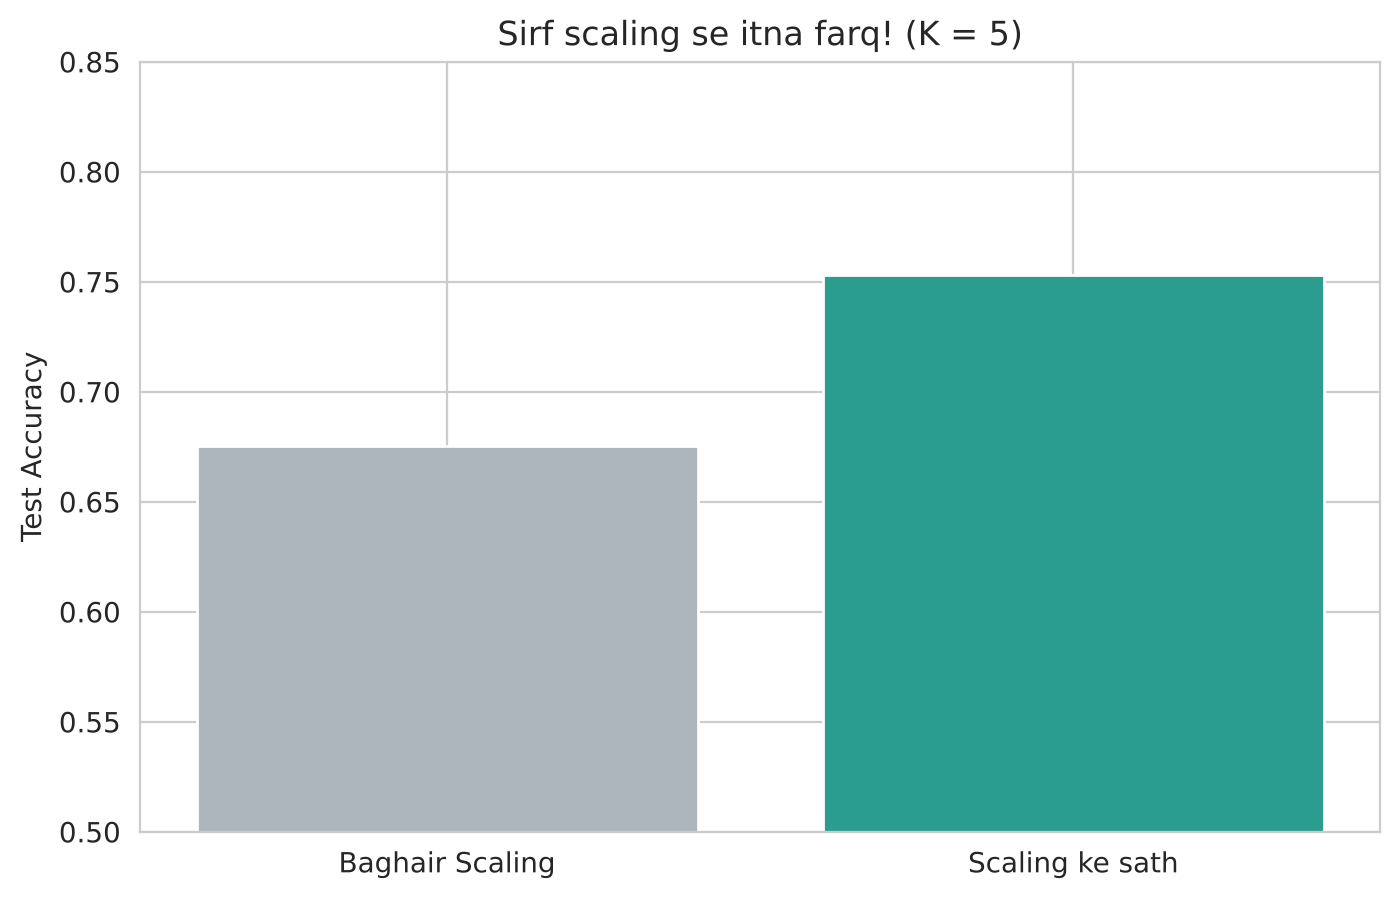

In [8]:
without_scaling = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model",   KNeighborsClassifier(n_neighbors=5))
])

with_scaling = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("model",   KNeighborsClassifier(n_neighbors=5))
])

without_scaling.fit(X_train, y_train)
with_scaling.fit(X_train, y_train)

acc_without = accuracy_score(y_test, without_scaling.predict(X_test))
acc_with = accuracy_score(y_test, with_scaling.predict(X_test))

print(f"Scaling ke BAGHAIR accuracy: {acc_without:.1%}")
print(f"Scaling ke SATH accuracy:    {acc_with:.1%}  ✅")

plt.bar(["Baghair Scaling", "Scaling ke sath"], [acc_without, acc_with], color=["#adb5bd", "#2A9D8F"])
plt.ylim(0.5, 0.85)
plt.ylabel("Test Accuracy")
plt.title("Sirf scaling se itna farq! (K = 5)")
plt.show()

**Sirf ek line (StandardScaler) se accuracy kaafi upar chali gayi!** 🚀

> 💡 **Yaad rakho:** Jo bhi algorithm **distance** pe chalta hai (KNN, K-Means, SVM), uske liay scaling **lazmi** hai.

---
## Step 5: K ka asar apni aankhon se dekhna 👀

Samajhne ke liay sirf **2 features (Glucose aur BMI)** lete hain aur graph pe dekhte hain ke model har jagah kya faisla karta hai. **Laal ilaqa** = model wahan Diabetes kahe ga, **neela ilaqa** = No Diabetes.

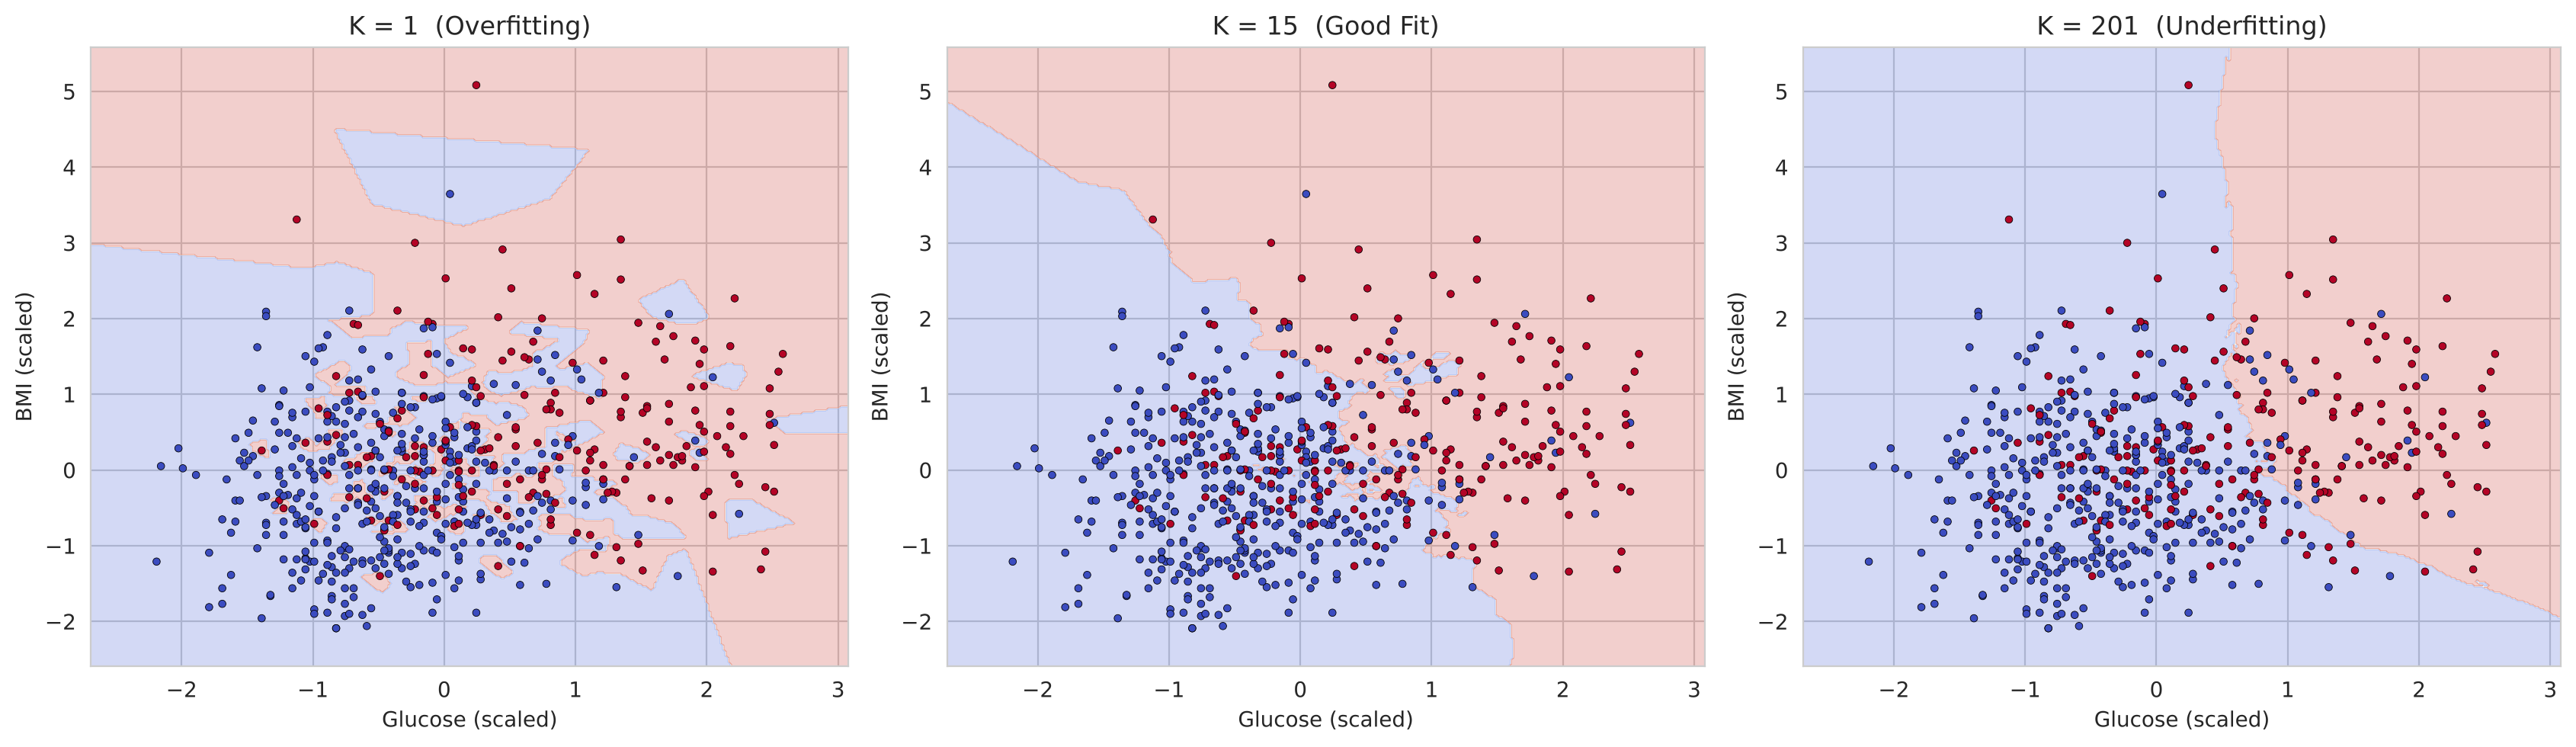

In [9]:
two = ["Glucose", "BMI"]
prep2 = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
X2 = prep2.fit_transform(X_train[two])

# Graph ke liay poore ilaqay ka jaal (grid)
xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 300),
                     np.linspace(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5, 300))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, k, label in zip(axes, [1, 15, 201], ["Overfitting", "Good Fit", "Underfitting"]):
    knn2 = KNeighborsClassifier(n_neighbors=k).fit(X2, y_train)
    Z = knn2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(X2[:, 0], X2[:, 1], c=y_train, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(f"K = {k}  ({label})")
    ax.set_xlabel("Glucose (scaled)")
    ax.set_ylabel("BMI (scaled)")
plt.tight_layout()
plt.show()

**Teeno graph samjho:**

| K | Kya ho raha hai | Misaal |
|---|---|---|
| **K = 1** | Har akele point ke gird chhote chhote tapu (islands). Model har ek mareez ko **ratta** maar raha hai, galti wale (noise) points ko bhi | Sirf ek dost ki baat sun kar faisla karna 🙉 |
| **K = 15** | Ilaqay saaf aur smooth. Glucose zyada ➜ laal. Model ne **asal pattern** seekha | Mohallay ke 15 logon se mashwara 👍 |
| **K = 201** | Boundary ek moti si seedhi deewar ban gayi. Model ne BMI ki baareekiyan chhor di aur beech wale bohat se mareez neele ilaqay mein chale gaye, kyunke itne zyada padosiyon mein majority hamesha "No Diabetes" ki hoti hai | Poore shehar ki raye le lena, apne mohallay ka farq hi kho gaya 🤷 |

**K chhota** = Overfitting, **K bohat bara** = Underfitting. Sahi K beech mein kahin hai. Chalo dhoondte hain!

---
## Step 6: Best K dhoondna (Cross Validation) 🔄

Saare 8 features ke sath, odd values K = 1, 3, 5 ... 31 try karein ge. Test data ko chhuay baghair, training data pe 5-fold Cross Validation.

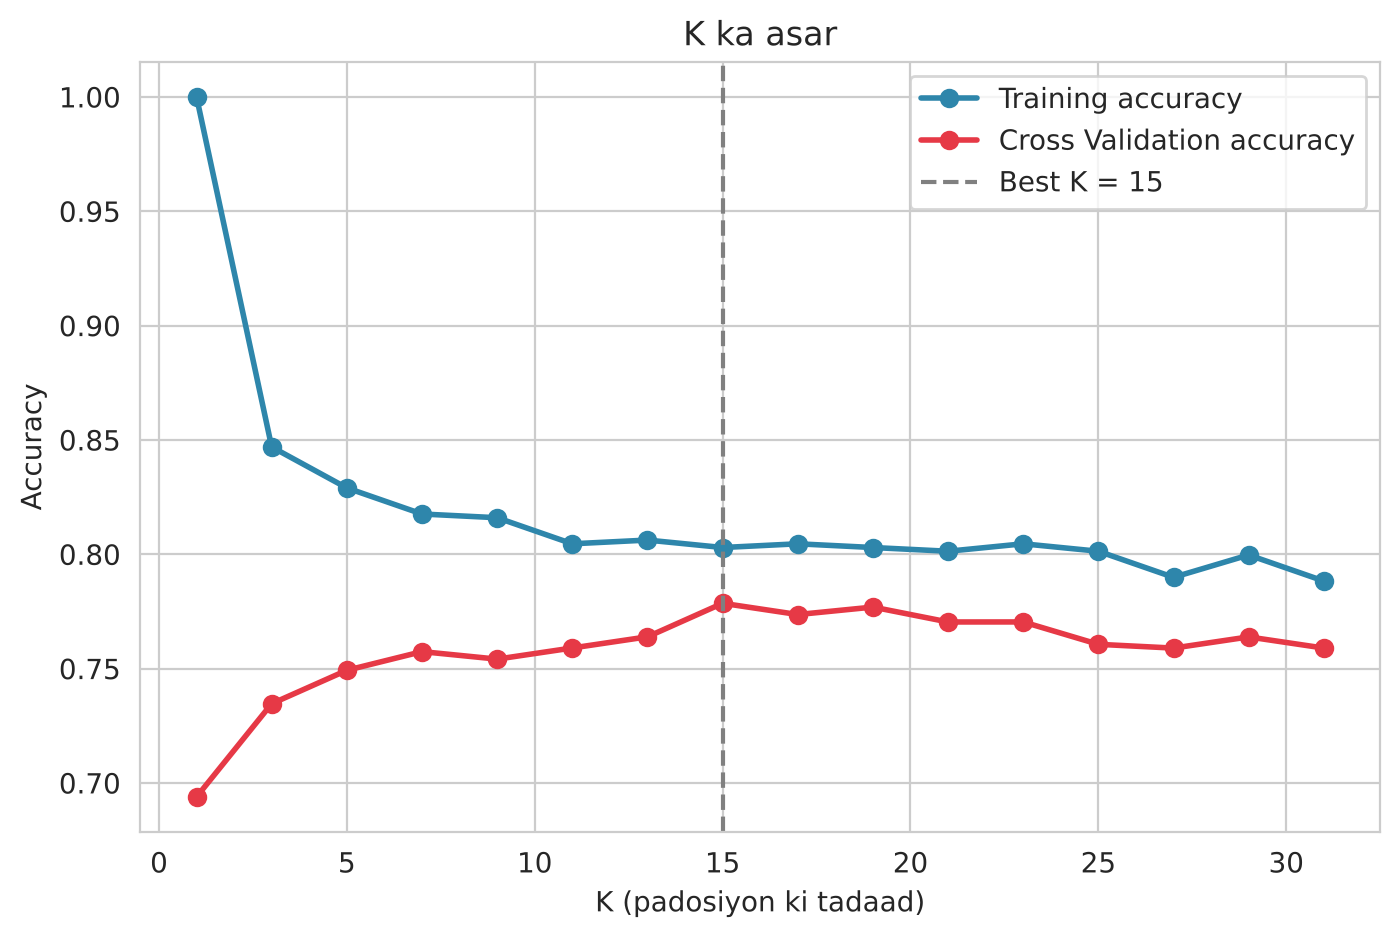

Best K: 15 | CV Accuracy: 77.9%


In [10]:
def make_knn(k, weights="uniform"):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("model",   KNeighborsClassifier(n_neighbors=k, weights=weights))
    ])

k_values = list(range(1, 32, 2))   # sirf odd numbers
train_scores, cv_scores = [], []

for k in k_values:
    m = make_knn(k)
    cv_scores.append(cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy").mean())
    train_scores.append(m.fit(X_train, y_train).score(X_train, y_train))

best_k = k_values[int(np.argmax(cv_scores))]

plt.plot(k_values, train_scores, "o-", color="#2E86AB", linewidth=2, label="Training accuracy")
plt.plot(k_values, cv_scores, "o-", color="#E63946", linewidth=2, label="Cross Validation accuracy")
plt.axvline(best_k, color="gray", linestyle="--", label=f"Best K = {best_k}")
plt.xlabel("K (padosiyon ki tadaad)")
plt.ylabel("Accuracy")
plt.title("K ka asar")
plt.legend()
plt.show()

print("Best K:", best_k, f"| CV Accuracy: {max(cv_scores):.1%}")

**Graph samjho:**
- **K = 1** pe Training accuracy **100%** hai! Kyun? Kyunke har training point ka sab se qareebi padosi **wo khud** hai. 😄 Lekin CV accuracy sab se kam. Ye pakki **overfitting** hai.
- K barhne ke sath CV accuracy behtar hoti hai, phir ek jagah ke baad flat ya thori kam.
- Code ne khud **best K** chun liya.

### `weights` parameter ⚖️
Default mein har padosi ka vote **barabar** hota hai (`weights="uniform"`). Lekin kya ye theek hai ke bilkul saath khara padosi aur door wala padosi barabar ahmiyat rakhein?

`weights="distance"` mein **qareeb wale padosi ka vote zyada wazni** hota hai. Dono try karte hain:

In [11]:
for w in ["uniform", "distance"]:
    score = cross_val_score(make_knn(best_k, w), X_train, y_train, cv=5).mean()
    print(f"weights = '{w}':  CV Accuracy = {score:.1%}")

weights = 'uniform':  CV Accuracy = 77.9%
weights = 'distance':  CV Accuracy = 78.0%


Is data pe dono lagbhag barabar hain, isliay hum simple wala (`uniform`) hi rakhein ge. Lekin dosre datasets pe `distance` kabhi kabhi bohat farq dalta hai, isliay hamesha try zaroor karo.

---
## Step 7: Final model aur Evaluation 🏁

In [12]:
knn = make_knn(best_k)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
y_prob = knn.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.1%}\n")
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

Accuracy: 74.0%

              precision    recall  f1-score   support

 No Diabetes       0.78      0.84      0.81       100
    Diabetes       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



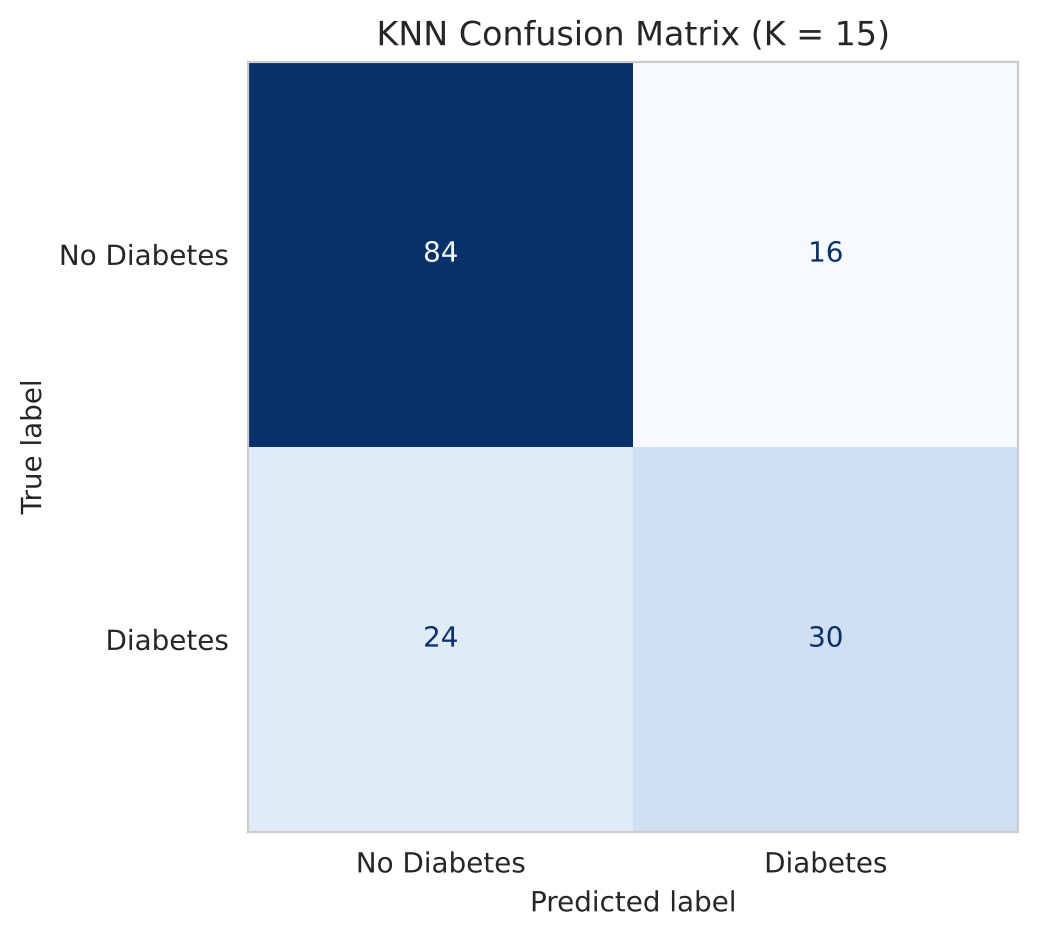

In [13]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["No Diabetes", "Diabetes"]).plot(cmap="Blues", colorbar=False)
plt.title(f"KNN Confusion Matrix (K = {best_k})")
plt.grid(False)
plt.show()

Pichli class wali kahani yahan bhi hai: Accuracy theek hai, lekin **Recall** (kitne mareez pakray) itna acha nahi. Medical ke liay ye kaafi nahi.

### KNN mein probability kaise aati hai? 🤔
Bohat simple! **Padosiyon mein kitne diabetes wale the.** K = 15 mein agar 9 padosiyon ko diabetes thi, to chance = 9/15 = **60%**.

Isliay hum yahan bhi **threshold** kam kar sakte hain:

In [14]:
rows = []
for t in [0.3, 0.4, 0.5]:
    pred_t = (y_prob >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Accuracy": round(accuracy_score(y_test, pred_t), 3),
        "Precision": round(precision_score(y_test, pred_t), 3),
        "Recall": round(recall_score(y_test, pred_t), 3),
        "Chhoote mareez (FN)": int(((pred_t == 0) & (y_test == 1)).sum())
    })
pd.DataFrame(rows)

,Threshold,Accuracy,Precision,Recall,Chhoote mareez (FN)
0,0.3,0.701,0.551,0.796,11
1,0.4,0.727,0.594,0.704,16
2,0.5,0.740,0.652,0.556,24


Threshold 0.3 pe bohat zyada mareez pakray gaye (Recall upar), lekin is baar accuracy thori giri. Yahi **trade-off** hai: kuch sehatmand logon ko extra test ke liay bhejna parega. Screening ke liay ye qeemat theek hai. 👍

In [15]:
threshold = 0.3

---
## Step 8: KNN vs Logistic Regression 🥊

Wohi data, wohi split. Dono models ko ek sath compare karte hain:

In [16]:
logreg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("model",   LogisticRegression(max_iter=1000))
]).fit(X_train, y_train)

def scores(name, model):
    p = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return {"Model": name,
            "Accuracy": round(accuracy_score(y_test, p), 3),
            "Precision": round(precision_score(y_test, p), 3),
            "Recall": round(recall_score(y_test, p), 3),
            "F1": round(f1_score(y_test, p), 3),
            "AUC": round(roc_auc_score(y_test, prob), 3)}

pd.DataFrame([scores("Logistic Regression", logreg), scores(f"KNN (K = {best_k})", knn)])

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.708,0.600,0.500,0.545,0.813
1,KNN (K = 15),0.740,0.652,0.556,0.600,0.807


Is data pe KNN accuracy aur F1 mein **thora aage** hai, jabke AUC mein Logistic Regression thora aage hai. Matlab dono **lagbhag barabar** hain. Har data pe koi ek model hamesha jeet ta nahi, isliay ML engineers hamesha **kai models try kar ke** compare karte hain. 🧪

### KNN ke fayde aur nuqsaan

| ✅ Fayde | ❌ Nuqsaan |
|---|---|
| Samajhna bohat asaan | Bare data pe prediction **slow** (har baar saare points se distance) |
| Training ki zaroorat nahi | **Scaling ke baghair bekaar** |
| Curve wale (non-linear) patterns bhi pakar leta hai | Bohat zyada features hon to distance ka matlab kho jata hai |
| Classification aur Regression dono kar sakta hai | Poora training data save rakhna parta hai (pickle file bari) |

| | Logistic Regression | KNN |
|---|---|---|
| Training mein kya hota hai | Formula (coefficients) seekhta hai | Sirf data yaad karta hai |
| Prediction | Bohat tez ⚡ | Slow 🐢 |
| Hyperparameter | C, max_iter | K, weights |
| Faisla kaise | Sigmoid probability | Padosiyon ka vote |

---
# 💾 Step 9: Model ko Pickle file mein save karna

KNN "lazy" hai, isliay iski pickle file ke andar **poora training data** save hota hai (padosi dhoondne ke liay chahiye!). Isi wajah se KNN ki file Logistic Regression se bari hoti hai.

In [17]:
model_package = {
    "model": knn,
    "threshold": threshold,
    "k": best_k,
    "features": list(X.columns),
    "zero_means_missing": zero_not_possible
}

with open("diabetes_knn_model.pkl", "wb") as file:
    pickle.dump(model_package, file)

import os
print(f"Model save ho gaya: diabetes_knn_model.pkl ✅  ({os.path.getsize('diabetes_knn_model.pkl') / 1024:.0f} KB)")

Model save ho gaya: diabetes_knn_model.pkl ✅  (55 KB)


### Load kar ke naye mareez pe test karna, aur uske **padosi** dekhna 🧪

KNN ki khoobsurti ye hai ke ye apna faisla **samjha** sakta hai: "Ye dekho, tumhare jaise ye 15 log the, aur unme se itno ko diabetes thi." `kneighbors()` function hamein wo padosi dikha deta hai.

In [18]:
with open("diabetes_knn_model.pkl", "rb") as file:
    loaded = pickle.load(file)

def check_diabetes(pregnancies, glucose, blood_pressure, skin_thickness,
                   insulin, bmi, pedigree, age, package=loaded, show_neighbors=False):
    patient = pd.DataFrame([[pregnancies, glucose, blood_pressure, skin_thickness,
                             insulin, bmi, pedigree, age]], columns=package["features"])
    patient[package["zero_means_missing"]] = patient[package["zero_means_missing"]].replace(0, np.nan)

    model = package["model"]
    chance = model.predict_proba(patient)[0, 1]
    sick = round(chance * package["k"])
    result = "Diabetes ka khatra ⚠️" if chance >= package["threshold"] else "Khatra kam ✅"
    print(f"{package['k']} milte julte mareezon mein se {sick} ko diabetes thi")
    print(f"Diabetes ka chance: {chance:.0%}  ->  {result}")

    if show_neighbors:
        ready = model[:-1].transform(patient)                     # imputer + scaler
        _, idx = model.named_steps["model"].kneighbors(ready)    # padosi dhoondo
        neighbors = X_train.iloc[idx[0]].copy()
        neighbors["Outcome"] = y_train.iloc[idx[0]].values
        return neighbors[["Glucose", "BMI", "Age", "Insulin", "Outcome"]].head(8)


check_diabetes(pregnancies=1, glucose=95, blood_pressure=70, skin_thickness=25,
               insulin=80, bmi=23.5, pedigree=0.3, age=25)
print()
check_diabetes(pregnancies=6, glucose=170, blood_pressure=85, skin_thickness=35,
               insulin=0, bmi=36.0, pedigree=0.8, age=50, show_neighbors=True)

15 milte julte mareezon mein se 0 ko diabetes thi
Diabetes ka chance: 0%  ->  Khatra kam ✅

15 milte julte mareezon mein se 12 ko diabetes thi
Diabetes ka chance: 80%  ->  Diabetes ka khatra ⚠️


,Glucose,BMI,Age,Insulin,Outcome
603,150.0,35.2,54,126.0,1
0,148.0,33.6,50,NaN,1
516,145.0,30.3,53,165.0,1
754,154.0,32.4,45,NaN,1
209,184.0,35.5,41,NaN,1
702,168.0,35.0,52,NaN,1
588,176.0,33.3,52,156.0,1
22,196.0,39.8,41,NaN,1


Upar wali table mein dekho (`NaN` ka matlab us mareez ka Insulin missing tha), model ne jo padosi dhoonde unka **Glucose aur BMI bhi zyada** hai, bilkul naye mareez ki tarah. Isi liay unme se zyada tar ko diabetes thi. KNN ka faisla **samajh mein aane wala** hai. 🔍

> ⚠️ Kabhi bhi anjaan insaan ki di hui `.pkl` file load na karo, usme chhupa code ho sakta hai. 🔒

> 💡 **Colab mein file download karni ho:**
> ```python
> from google.colab import files
> files.download("diabetes_knn_model.pkl")
> ```

---
## 📚 Summary: Aaj humne kya seekha

1. **KNN:** Naye point ke **K sab se qareebi padosi** dhoondo, aur unki **majority vote** se faisla karo
2. **Euclidean Distance:** Pythagoras wala formula, do points ke beech seedhi line
3. **Lazy Learner:** KNN training mein kuch nahi seekhta, bas data yaad karta hai. Koi epoch nahi
4. **Scaling lazmi hai:** Warna bari values wale features distance pe qabza kar lete hain
5. **K chhota = Overfitting, K bara = Underfitting.** K hamesha **odd** rakho aur Cross Validation se chuno
6. **weights="distance":** Qareeb wale padosi ka vote zyada wazni
7. KNN ki probability = padosiyon mein diabetes walon ka hissa. **Threshold** yahan bhi kaam karta hai
8. Pickle mein poora training data save hota hai, aur `kneighbors()` se faisle ki wajah (padosi) dekh sakte hain

---
## ✍️ Homework / Practice

1. Step 4 mein `n_neighbors=5` ko `1` kar ke dekho. Scaling ke sath aur baghair, dono ki accuracy kya aayi?
2. Step 5 mein K = 1, 15, 201 ki jagah **K = 3, 51, 401** try karo. Graph kaise badle?
3. `KNeighborsClassifier(..., metric="manhattan")` try karo. Manhattan distance mein seedhi line ki jagah **shehar ki galiyon** ki tarah (pehle seedha, phir mur kar) distance naapte hain. 🏙️ Accuracy pe kya asar hua?
4. Apni marzi ke mareez `check_diabetes(..., show_neighbors=True)` mein daal kar uske padosi dekho
5. **Socho:** Agar hamare paas 1 crore mareezon ka data ho, to KNN se prediction mein kya masla aaye ga?

**Shabash! Ab aapke paas do classification models hain aur aap unka muqabla bhi kar sakte ho. 🎓**